In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent))  # project root containing app/

%load_ext autoreload
%autoreload 2

from app.config import BASE_DIR
print(BASE_DIR, (BASE_DIR / ".env").exists())

/Volumes/Personal/projects/fastapi/deepwell True


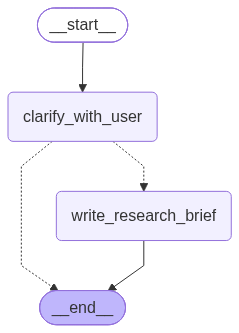

In [ ]:
from app.agents.scope.agent import build

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.config import RunnableConfig

agent = build()


display(Image(agent.get_graph().draw_mermaid_png()))

In [5]:
config: RunnableConfig = {"configurable": {"thread_id": "1", "user_id" : "rizwan"}}
from langchain_core.messages import HumanMessage

response = await agent.ainvoke({"messages": [HumanMessage(content="I have BS in computer science, i am looking to find MS programs in Germany")]}, config=config)

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

I have BS in computer science, i am looking to find MS programs in Germany
================================== Ai Message ==================================

Are you looking for MS programs in computer science specifically, or are you open to related fields as well?


In [42]:
import app.agents.scope.prompts as p
import app.agents.scope.agent as g

print(p.__file__)
print(g.__file__)
print('"need_clarification"' in p.SCOPING_PROMPT)
print('"need_clarification"' in g.SCOPING_PROMPT)

/Volumes/Personal/projects/fastapi/deepwell/app/agents/scope/prompts.py
/Volumes/Personal/projects/fastapi/deepwell/app/agents/scope/agent.py
False
True


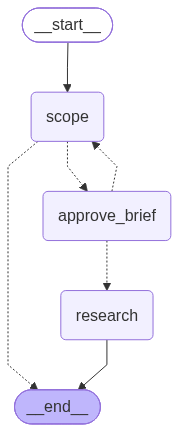

In [6]:
from app.agents.deepwell.agent import build

checkpointer = InMemorySaver()
store = InMemoryStore()
agent = build(checkpointer=checkpointer, store=store)

display(Image(agent.get_graph().draw_mermaid_png()))

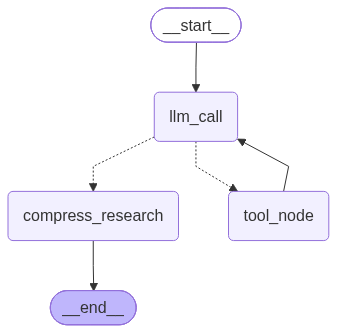

In [4]:
from app.agents.research.agent import agent
from dotenv import load_dotenv

load_dotenv()
display(Image(agent.get_graph().draw_mermaid_png()))

In [ ]:
from langchain_core.messages import HumanMessage

research_brief = """I want to identify and evaluate the coffee shops in San Francisco that are considered the best based specifically  
on coffee quality. My research should focus on analyzing and comparing coffee shops within the San Francisco area, 
using coffee quality as the primary criterion. I am open regarding methods of assessing coffee quality (e.g.,      
expert reviews, customer ratings, specialty coffee certifications), and there are no constraints on ambiance,      
location, wifi, or food options unless they directly impact perceived coffee quality. Please prioritize primary    
sources such as the official websites of coffee shops, reputable third-party coffee review organizations (like     
Coffee Review or Specialty Coffee Association), and prominent review aggregators like Google or Yelp where direct  
customer feedback about coffee quality can be found. The study should result in a well-supported list or ranking of
the top coffee shops in San Francisco, emphasizing their coffee quality according to the latest available data as  
of October 2026."""

agent.invoke({"researcher_messages": [HumanMessage(content=research_brief)]})

ValidationError: 2 validation errors for AgentState
research_brief
  Field required [type=missing, input_value={'researcher_messages': [], 'raw_notes': []}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.13/v/missing
compressed_research
  Field required [type=missing, input_value={'researcher_messages': [], 'raw_notes': []}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.13/v/missing